# Practice Session 04: Weighted Networks


Martí Pascual Barluenga u232620

# 1. Read mapping of codes to country names

In [1]:
import csv
import io
import networkx as nx
import matplotlib.pyplot as plt
import math
import pandas as pd

In [2]:
# Leave this cell as-is

INPUT_NAMES_FILENAME = "trade-countries.csv"
INPUT_TRADE_OLD = "trade-2012-flows.csv"
YEAR_OLD = 2012
INPUT_TRADE_NEW = "trade-2022-flows.csv"
YEAR_NEW = 2022

In [3]:
id2name = {}

In [4]:
with open(INPUT_NAMES_FILENAME, "rt") as input_file:

    reader = csv.DictReader(input_file, delimiter='\t')

    for record in reader:
        print(record)
        id2name[record['code']] = record['name']
        

{'code': 'AUS', 'name': 'Australia'}
{'code': 'AUT', 'name': 'Austria'}
{'code': 'BEL', 'name': 'Belgium'}
{'code': 'CAN', 'name': 'Canada'}
{'code': 'CHE', 'name': 'Switzerland'}
{'code': 'CHL', 'name': 'Chile'}
{'code': 'CZE', 'name': 'Czech Republic'}
{'code': 'DEU', 'name': 'Germany'}
{'code': 'DNK', 'name': 'Denmark'}
{'code': 'ESP', 'name': 'Spain'}
{'code': 'EST', 'name': 'Estonia'}
{'code': 'FIN', 'name': 'Finland'}
{'code': 'FRA', 'name': 'France'}
{'code': 'GBR', 'name': 'United Kingdom'}
{'code': 'GRC', 'name': 'Greece'}
{'code': 'HUN', 'name': 'Hungary'}
{'code': 'IRL', 'name': 'Ireland'}
{'code': 'ISL', 'name': 'Iceland'}
{'code': 'ISR', 'name': 'Israel'}
{'code': 'ITA', 'name': 'Italy'}
{'code': 'JPN', 'name': 'Japan'}
{'code': 'LUX', 'name': 'Luxembourg'}
{'code': 'MEX', 'name': 'Mexico'}
{'code': 'NLD', 'name': 'Netherlands'}
{'code': 'NOR', 'name': 'Norway'}
{'code': 'NZL', 'name': 'New Zealand'}
{'code': 'POL', 'name': 'Poland'}
{'code': 'PRT', 'name': 'Portugal'}
{'c

In [5]:
# LEAVE AS-IS, it should print "Norway"

print(id2name["NOR"])

Norway


# 2. Read flows data into two graphs

## 2.1. Read amount traded

In [6]:
gOld = nx.DiGraph()
gNew = nx.DiGraph()

def read_trade_data(filename, graph):
    with open(filename, "rt") as input_file:
        reader = csv.DictReader(input_file, delimiter='\t')
        for record in reader:
            from_country = record['from']
            to_country = record['to']
            if from_country in id2name and to_country in id2name:
                amount = round(float(record['amount']) / 1_000_000)
                graph.add_edge(from_country, to_country, weight=amount)

read_trade_data(INPUT_TRADE_OLD, gOld)
read_trade_data(INPUT_TRADE_NEW, gNew)

In [7]:
# LEAVE AS-IS

print("The {:d} graph contains {:d} nodes".format(YEAR_OLD, gOld.number_of_nodes()))
print("The {:d} graph contains {:d} nodes".format(YEAR_NEW, gNew.number_of_nodes()))

The 2012 graph contains 33 nodes
The 2022 graph contains 33 nodes


The following should print:

```
In 2012, ESP (Spain) exported to SVK (Slovak Republic) goods and services for 777 USD millions
by 2022, it exported 1,548 USD millions

In 2012, ESP (Spain) exported to ITA (Italy) goods and services for 21,601 USD millions
by 2022, it exported 32,225 USD millions

In 2012, USA (United States) exported to SVK (Slovak Republic) goods and services for 333 USD millions
by 2022, it exported 376 USD millions

In 2012, USA (United States) exported to ITA (Italy) goods and services for 15,972 USD millions
by 2022, it exported 27,411 USD millions
```

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [8]:
# LEAVE AS-IS

for exporter in ["ESP", "USA"]:
    for importer in ["SVK", "ITA"]:
        print("In {:d}, {:s} ({:s}) exported to {:s} ({:s}) goods and services for {:,d} USD millions".format(
            YEAR_OLD, exporter, id2name[exporter], importer, id2name[importer],
               gOld.get_edge_data(exporter, importer)["weight"]) )

        print("by {:d}, it exported {:,d} USD millions".format(YEAR_NEW, gNew.get_edge_data(exporter, importer)["weight"]))
        print("")
    

In 2012, ESP (Spain) exported to SVK (Slovak Republic) goods and services for 777 USD millions
by 2022, it exported 1,548 USD millions

In 2012, ESP (Spain) exported to ITA (Italy) goods and services for 21,601 USD millions
by 2022, it exported 32,225 USD millions

In 2012, USA (United States) exported to SVK (Slovak Republic) goods and services for 333 USD millions
by 2022, it exported 376 USD millions

In 2012, USA (United States) exported to ITA (Italy) goods and services for 15,972 USD millions
by 2022, it exported 27,411 USD millions



## 2.2. Compute totals

In [9]:
def sum_weights(graph, direction, weight_key="weight"):
    totals = dict([(element, 0) for element in graph.nodes()])
    if direction == "out":
        for u, v, d in graph.edges(data=True):
            totals[u] += d[weight_key]
    elif direction == "in":
        for u, v, d in graph.edges(data=True):
            totals[v] += d[weight_key]
    return totals

exportsOld = sum_weights(gOld, "out")
importsOld = sum_weights(gOld, "in")
exportsNew = sum_weights(gNew, "out")
importsNew = sum_weights(gNew, "in")

In [10]:
# LEAVE AS-IS

for country in ['EST', 'ESP', 'TUR']:
    print("{:s} exported {:,d} USD Million in {:d} and {:,d} USD Million in {:d} (growth {:.1f}x),".format(
        id2name[country],
        exportsOld[country], YEAR_OLD,
        exportsNew[country], YEAR_NEW,
        exportsNew[country]/exportsOld[country]
    ))
    print(" and imported {:,d} USD Million in {:d} and {:,d} USD Million in {:d} (growth {:.1f}x).".format(
        importsOld[country], YEAR_OLD,
        importsNew[country], YEAR_NEW,
        importsNew[country]/importsOld[country]
    ))
    print()

Estonia exported 10,082 USD Million in 2012 and 14,312 USD Million in 2022 (growth 1.4x),
 and imported 11,401 USD Million in 2012 and 10,463 USD Million in 2022 (growth 0.9x).

Spain exported 214,025 USD Million in 2012 and 313,679 USD Million in 2022 (growth 1.5x),
 and imported 208,224 USD Million in 2012 and 234,182 USD Million in 2022 (growth 1.1x).

TÃ¼rkiye exported 66,536 USD Million in 2012 and 133,088 USD Million in 2022 (growth 2.0x),
 and imported 112,203 USD Million in 2012 and 110,220 USD Million in 2022 (growth 1.0x).



In [11]:
# LEAVE AS-IS

sorted_countries = sorted(id2name.keys())

flowsData = {
    'expOld': [(exportsOld[c] if c in exportsOld else 0) for c in sorted_countries],
    'impOld': [(importsOld[c] if c in importsOld else 0) for c in sorted_countries],
    'expNew': [(exportsNew[c] if c in exportsNew else 0) for c in sorted_countries], 
    'impNew': [(importsNew[c] if c in importsNew else 0) for c in sorted_countries],
}

flowsDF = pd.DataFrame(flowsData, index=sorted_countries)
flowsDF

,expOld,impOld,expNew,impNew
AUS,71773,108802,97914,93347
AUT,130958,144673,177134,149509
BEL,244684,303104,383111,289290
CAN,393860,361999,531428,431171
CHE,204660,211169,273772,222134
CHL,34975,35969,33794,38953
CZE,133716,106840,214859,130849
DEU,1044010,836190,1284888,855477
DNK,86293,72924,85535,79871
ESP,214025,208224,313679,234182


# 3. Draw the exports graphs

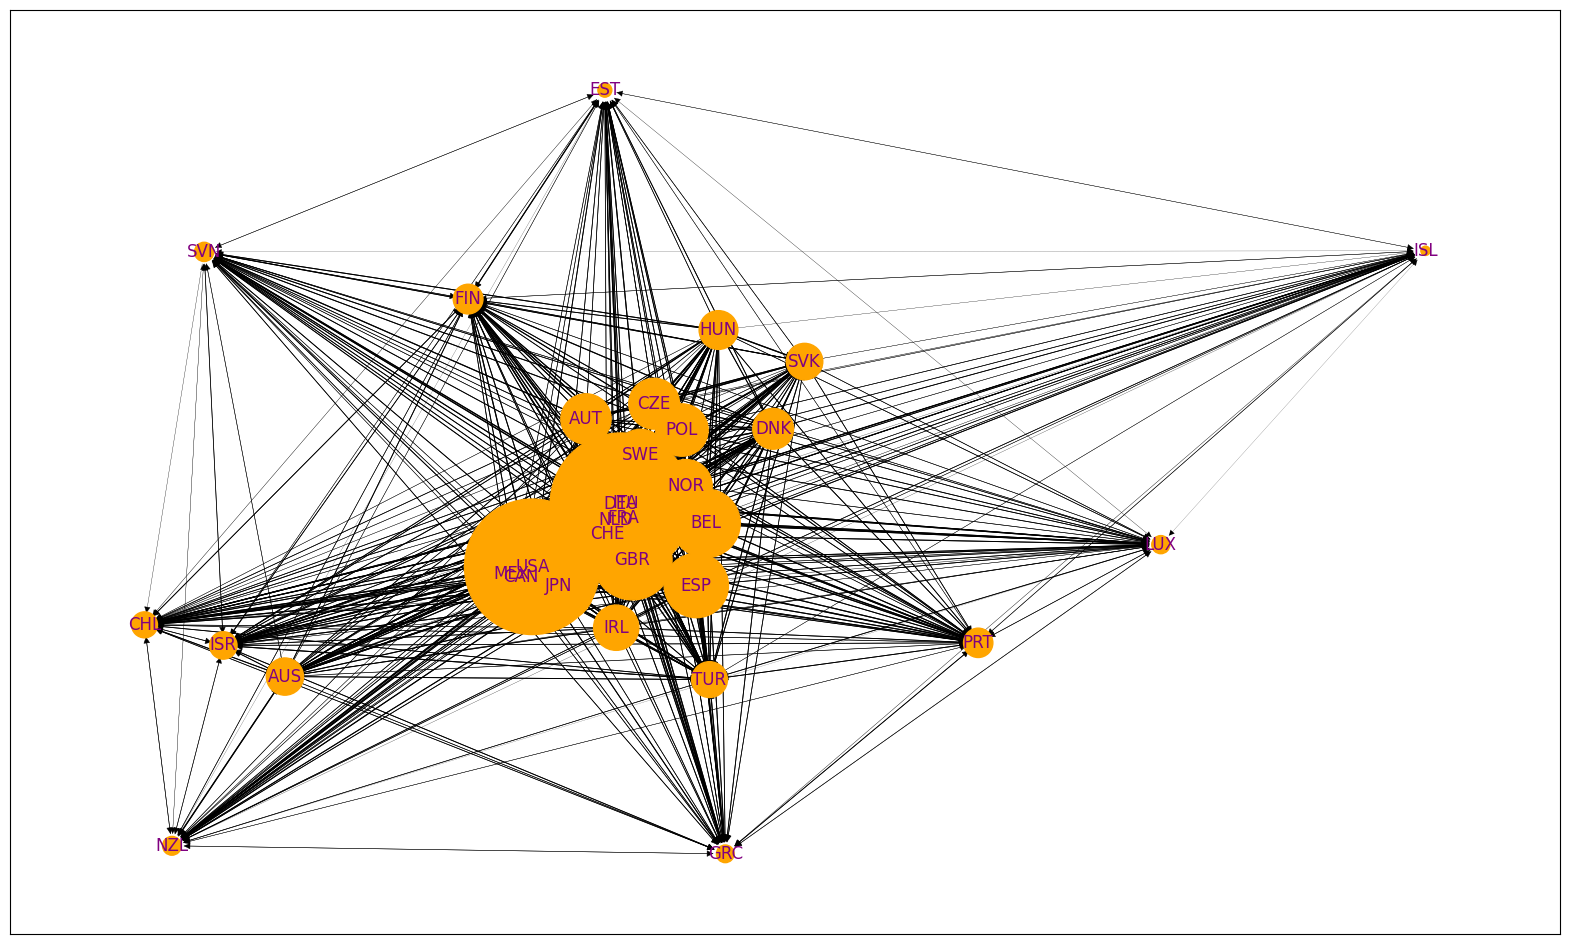

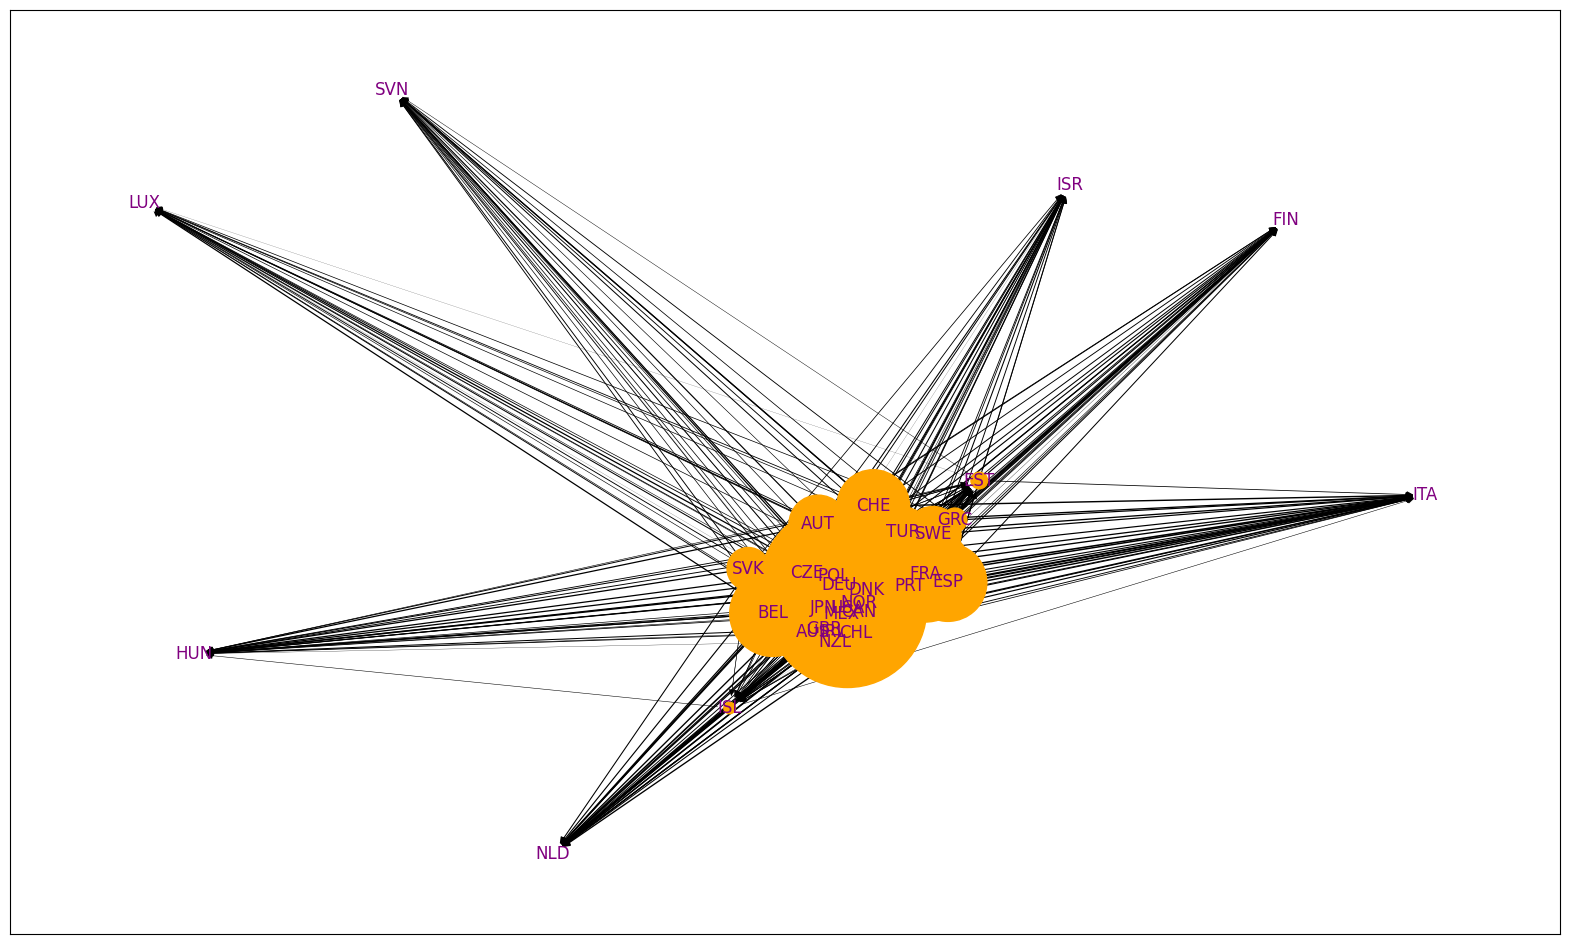

In [33]:
NODE_SIZE_MULTIPLIER = 0.01
EDGE_WIDTH_MULTIPLIER = 0.1

def plotGraph(g, exports):
    plt.figure(figsize=(20, 12))

    node_sizes = []
    for node in g.nodes:
        node_sizes.append(exports[node] * NODE_SIZE_MULTIPLIER)

    edge_widths = []
    for u, v, d in g.edges(data=True):
        weight = d.get('weight', 0)
        if weight > 0:
            edge_width = math.log(weight) * EDGE_WIDTH_MULTIPLIER
        else:
            edge_width = 0
        edge_widths.append(edge_width)

    pos = nx.spring_layout(g, iterations=100, weight="weight")
    nx.draw_networkx_nodes(g, pos, node_color="orange", node_size=node_sizes)
    nx.draw_networkx_edges(g, pos, width=edge_widths)
    labels = nx.draw_networkx_labels(g, pos, font_color="purple")
    plt.show()

plotGraph(gOld, exportsOld)
plotGraph(gNew, exportsNew)


<font size="+1" color="red">Replace this cell with (1) a brief commentary on what are the similarities and differences you observe between these two graphs and (2) the answer to the following: identify and discuss any 3 countries that serve as major trade hubs. How consistent are their positions across both years, and what might this indicate about their roles in international trade?</font>



(1)->The main diferences betwen this two graphs are that, in the first picture, the small nodes that round the central block of nodes in the periferic like Australia and Finland are connected beetwen them and all the central nodes point outwards to the small ones. In the second picture, the periferic nodes like Luxemburg and Finland, are not connected betwen them and are only connected to the centrall nodes. The centrall nodes like in the first graph point outward.
The similarities between the two graphs are that the central nodes that are central trade hubs are maintained the same during the years.

(2) -> Three countries that serve as major trade hubs are Germany, United States, and France. 
In both years this countires are centrall and large nodes. These 3 countries have consistent positions as trade hubs suggest their pivotal roles in the graph. 

# 4. Comparison of export and import scores

In [39]:
def plot_scatter(a, b, xlabel, ylabel):

    filtered_a = {k: v for k, v in a.items() if v > 0 and b[k] > 0}
    filtered_b = {k: v for k, v in b.items() if v > 0 and a[k] > 0}

    plt.figure(figsize=(20, 10))
    plt.loglog()
    plt.xlabel(xlabel, {'size': '22'})
    plt.ylabel(ylabel, {'size': '22'})

    plt.plot([min(filtered_a.values()), max(filtered_a.values())], 
             [min(filtered_b.values()), max(filtered_b.values())], '-.', lw=2)

    for country in set(filtered_a.keys()).intersection(set(filtered_b.keys())):
        plt.text(filtered_a[country], filtered_b[country], country, {'size': '12'})

    plt.show()


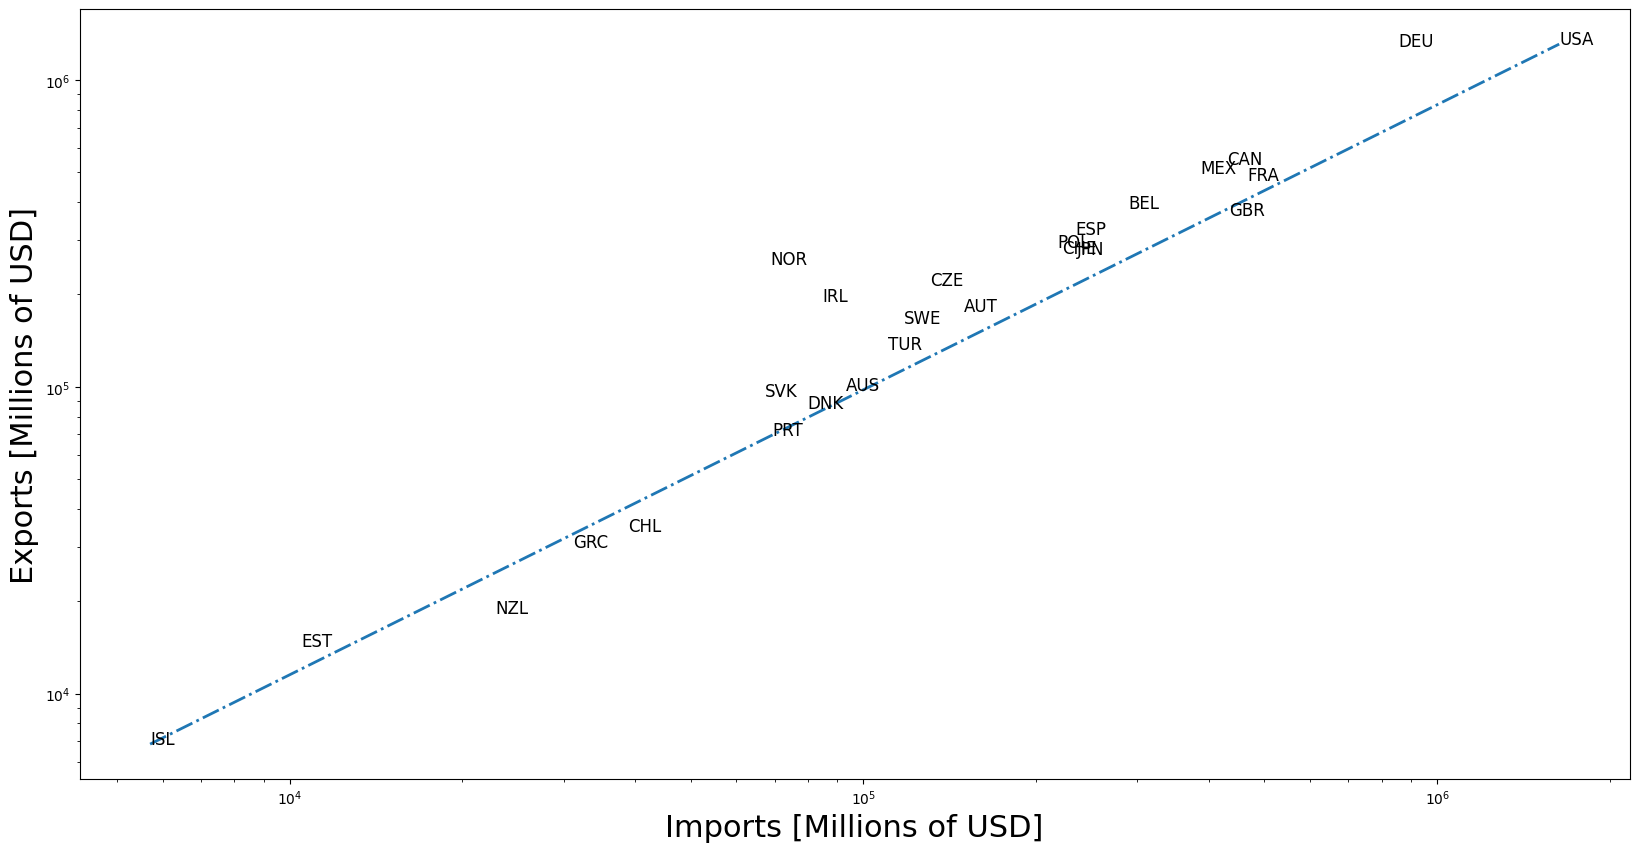

In [40]:
# LEAVE AS-IS: print plots for the newer dataset

plot_scatter( importsNew, exportsNew, "Imports [Millions of USD]", "Exports [Millions of USD]" )

The plot above is very interesting for understanding the economics of imports and exports in different countries. The central line indicates the countries that have a balanced level of imports and exports. The countries above the line have more exports than imports, while those below have more imports than exports. We can observe that the USA is one of the most important countries in global commerce and has a balanced level of imports and exports.

# DELIVER (individually)

A .zip file containing:

* This notebook.


<font size="+2" color="#003300">I hereby declare that, except for the code provided by the course instructors, all of my code, report, and figures were produced by myself.</font>